# Portuguese Bank Marketing — Final Submission Notebook (PRCP-1000)

**Dataset:** UCI Bank Marketing, `bank-additional-full.csv` — 41,188 rows x 21 columns, target `y` (did the client subscribe to a term deposit: yes / no). Data from a Portuguese bank's direct marketing campaigns (2008-2010).

**Final pick : Gradient Boosting (balanced) @ 0.5** — F1 49.43%, AUC 0.8152, recall 65.73% (610 of 928 subscribers).


## Contents

**Task 1 — Data Analysis**
1. Load the data
2. Shape, columns and target distribution
3. Duplicates, missing values and 'unknown' values
4. Numeric summary
5. Target rate by group
6. Leakage check — `duration`
7. Key findings for modelling

**Task 2 — Classification**
8. Preprocessing — duplicates, target encoding, leakage column, one-hot encoding
9. Scaling + stratified 80/20 split
10. First models — Logistic Regression vs Random Forest
11. Fixing the imbalance — balanced LR + RF + Gradient Boosting
12. Threshold tuning
13. Small hyperparameter check on Gradient Boosting
14. Lock the final model + save it
15. Feature importance — what drives the final model

**Task 3 — Model Comparison & Challenges Reports**
16. Final comparison (all models, one table)
17. Model Comparison Report
18. Challenges Report


## Task 1 — Data Analysis

### 1. Load the data


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Data Science project layout: the notebook lives in notebooks/, the dataset in data/,
# and outputs go to models/ and reports/. These paths also work from a flat folder.
_root = '..' if os.path.exists('../data/bank-additional-full.csv') else '.'
DATA_PATH = os.path.join(_root, 'data', 'bank-additional-full.csv') if _root == '..' else 'bank-additional-full.csv'
MODEL_PATH = os.path.join(_root, 'models', 'Portuguese_final_model.pkl') if _root == '..' else 'Portuguese_final_model.pkl'
REPORT_PATH = os.path.join(_root, 'reports', 'Portuguese_model_comparison_final.csv') if _root == '..' else 'Portuguese_model_comparison_final.csv'

# Change the filename below only if your dataset file has a different name.
df = pd.read_csv(DATA_PATH, sep=';')
print(df.shape)
df.head()


(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 2. Shape, columns and target distribution

**Verified on this file:** 41,188 rows x 21 columns. Target `y`: no = 36,548 (88.73%), yes = 4,640 (11.27%). The target is imbalanced — about 9 out of 10 clients said no — so accuracy alone will mislead later. Models are judged on recall / F1 / ROC-AUC for the "yes" class.


In [2]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nTarget counts:")
print(df['y'].value_counts())
print("\nTarget %:")
print((df['y'].value_counts(normalize=True) * 100).round(2))


Shape: (41188, 21)

Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Target counts:
y
no     36548
yes     4640
Name: count, dtype: int64

Target %:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


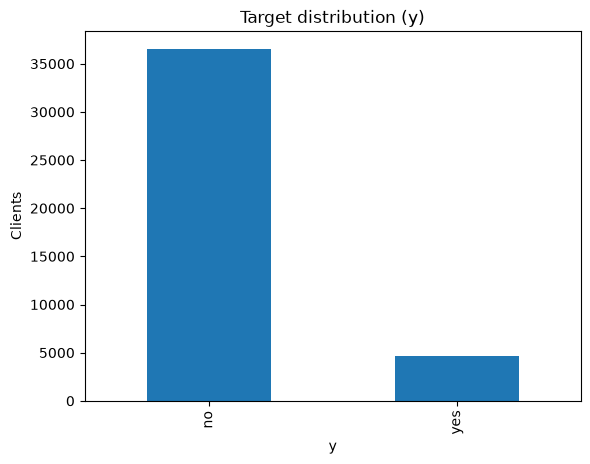

In [3]:
df['y'].value_counts().plot(kind='bar', title='Target distribution (y)')
plt.ylabel('Clients')
plt.show()


### 3. Duplicates, missing values and 'unknown' values

**Verified on this file:** 12 duplicate rows, 0 blank (NaN) cells. Missingness hides as the string `'unknown'` instead: `default` is 8,597 unknown (20.87%) — and only 3 clients actually have `default = yes`. `housing`, `loan`, `job`, `marital` and `education` also carry 'unknown' values. They are kept as their own category in Task 2, not deleted, so no client is thrown away.


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Blank (NaN) cells:", int(df.isna().sum().sum()))
print("\n'unknown' counts:")
for col in df.columns:
    n = (df[col].astype(str) == 'unknown').sum()
    if n:
        print(f"  {col}: {n} ({n / len(df) * 100:.2f}%)")


Duplicate rows: 12
Blank (NaN) cells: 0

'unknown' counts:
  job: 330 (0.80%)
  marital: 80 (0.19%)
  education: 1731 (4.20%)
  default: 8597 (20.87%)
  housing: 990 (2.40%)
  loan: 990 (2.40%)


### 4. Numeric summary

**Verified on this file:** age 17-98 (mean 40.0), duration 0-4,918 sec (median 180), campaign 1-56 contacts (mean 2.57), pdays 0-999, previous 0-7. Note `pdays = 999` for 96.32% of clients — that is the code for "never contacted before", not a real 999-day gap.


In [5]:
print(df.describe().round(2))
print("\npdays == 999 share:", round((df['pdays'] == 999).mean() * 100, 2), "%")
print("previous == 0 share:", round((df['previous'] == 0).mean() * 100, 2), "%")


            age  duration  campaign     pdays  previous  emp.var.rate  \
count  41188.00  41188.00  41188.00  41188.00  41188.00      41188.00   
mean      40.02    258.29      2.57    962.48      0.17          0.08   
std       10.42    259.28      2.77    186.91      0.49          1.57   
min       17.00      0.00      1.00      0.00      0.00         -3.40   
25%       32.00    102.00      1.00    999.00      0.00         -1.80   
50%       38.00    180.00      2.00    999.00      0.00          1.10   
75%       47.00    319.00      3.00    999.00      0.00          1.40   
max       98.00   4918.00     56.00    999.00      7.00          1.40   

       cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
count        41188.00       41188.00   41188.00     41188.00  
mean            93.58         -40.50       3.62      5167.04  
std              0.58           4.63       1.73        72.25  
min             92.20         -50.80       0.63      4963.60  
25%             93.08      

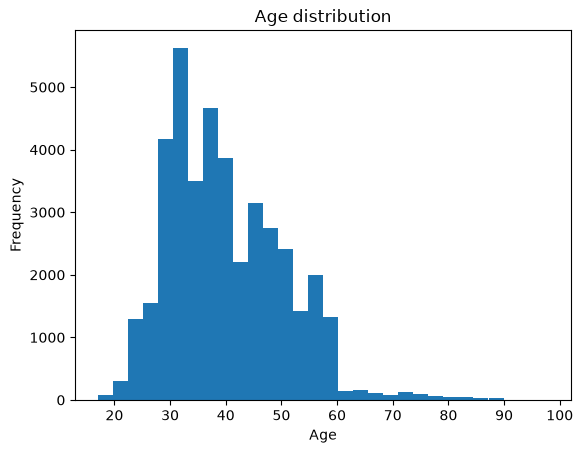

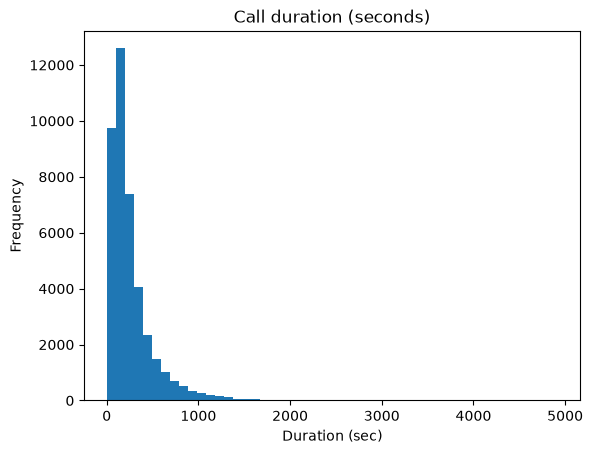

In [6]:
df['age'].plot(kind='hist', bins=30, title='Age distribution')
plt.xlabel('Age')
plt.show()
df['duration'].plot(kind='hist', bins=50, title='Call duration (seconds)')
plt.xlabel('Duration (sec)')
plt.show()


### 5. Target rate by group

**Verified on this file — subscribe rate (`y = yes`) by group:**
- Previous outcome (`poutcome`): success 65.1% vs failure 14.2% vs nonexistent 8.8% — the strongest single signal in the data.
- `job`: student 31.4% / retired 25.2% vs blue-collar 6.9%.
- `contact`: cellular beats telephone; `month`: March / December / September / October are the strong months.


In [7]:
for col in ['poutcome', 'contact', 'month', 'job', 'education']:
    rate = df.groupby(col)['y'].apply(lambda s: (s == 'yes').mean()).sort_values()
    print(f"\nSubscribe rate by {col}:")
    print((rate * 100).round(1))



Subscribe rate by poutcome:
poutcome
nonexistent     8.8
failure        14.2
success        65.1
Name: y, dtype: float64

Subscribe rate by contact:
contact
telephone     5.2
cellular     14.7
Name: y, dtype: float64

Subscribe rate by month:
month
may     6.4
jul     9.0
nov    10.1
jun    10.5
aug    10.6
apr    20.5
oct    43.9
sep    44.9
dec    48.9
mar    50.5
Name: y, dtype: float64

Subscribe rate by job:
job
blue-collar       6.9
services          8.1
entrepreneur      8.5
housemaid        10.0
self-employed    10.5
technician       10.8
unknown          11.2
management       11.2
admin.           13.0
unemployed       14.2
retired          25.2
student          31.4
Name: y, dtype: float64

Subscribe rate by education:
education
basic.9y                7.8
basic.6y                8.2
basic.4y               10.2
high.school            10.8
professional.course    11.3
university.degree      13.7
unknown                14.5
illiterate             22.2
Name: y, dtype: float64


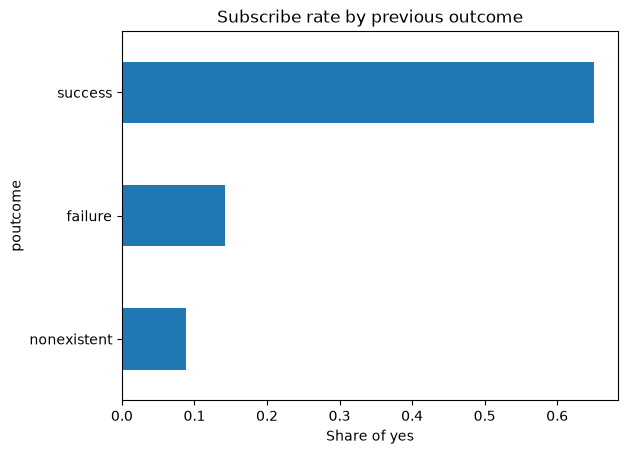

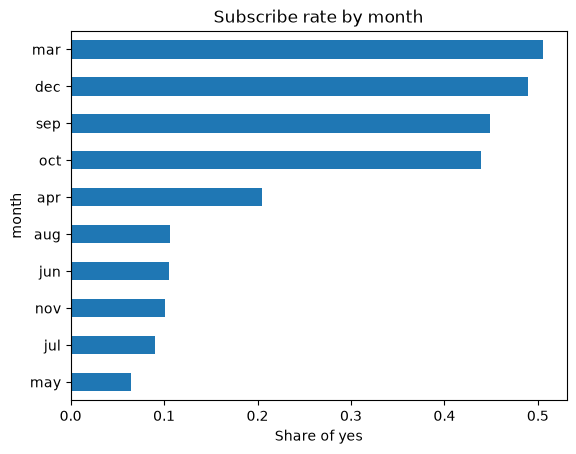

In [8]:
df.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean()).sort_values().plot(
    kind='barh', title='Subscribe rate by previous outcome')
plt.xlabel('Share of yes')
plt.show()
df.groupby('month')['y'].apply(lambda s: (s == 'yes').mean()).sort_values().plot(
    kind='barh', title='Subscribe rate by month')
plt.xlabel('Share of yes')
plt.show()


### 6. Leakage check — `duration`

**Verified on this file:** mean call duration is 553 sec for subscribers vs 221 sec for non-subscribers. By duration quartile the subscribe rate rises from 0.8% (shortest calls) to 29.2% (longest). That looks like the strongest feature in the data — but duration is known only **after** the call ends, so a campaign cannot use it to choose whom to call. It is **dropped before modelling** in Task 2. Keeping it would make the scores look better and the model useless.


In [9]:
print(df.groupby('y')['duration'].describe().round(1))
df['duration_quartile'] = pd.qcut(df['duration'], 4)
print("\nSubscribe rate by duration quartile:")
print((df.groupby('duration_quartile', observed=True)['y'].apply(lambda s: (s == 'yes').mean()) * 100).round(1))


       count   mean    std   min    25%    50%    75%     max
y                                                            
no   36548.0  220.8  207.1   0.0   95.0  163.5  279.0  4918.0
yes   4640.0  553.2  401.2  37.0  253.0  449.0  741.2  4199.0

Subscribe rate by duration quartile:
duration_quartile
(-0.001, 102.0]     0.8
(102.0, 180.0]      4.6
(180.0, 319.0]     10.6
(319.0, 4918.0]    29.2
Name: y, dtype: float64


### 7. Key findings and what they mean for modelling

1. **Imbalanced target** — 88.73% no / 11.27% yes. Use a stratified split, and judge models by recall / F1 / ROC-AUC for "yes", not accuracy alone. (Saying "no" to everyone already scores 88.73% accuracy while finding nobody.)
2. **Strongest honest signals** — previous outcome (`poutcome = success` → 65.1%), students and retired clients, and the economic indicators (`nr.employed`, `euribor3m`) at call time.
3. **Leakage** — `duration` is dropped before modelling.
4. **`pdays = 999`** means "never contacted before" (96.32% of clients), not a real gap.
5. **'unknown' is a category**, not a blank — kept as-is, so no client is deleted.


## Task 2 — Classification

### 8. Preprocessing

Decisions (all from the Task 1 analysis above):
- **Drop 12 duplicate rows** — exact copies, no information in them.
- **Encode the target:** `y = 1` for "yes", `0` for "no".
- **Drop `duration`** — leakage (known only after the call ends).
- **One-hot encode categoricals** — 'unknown' stays a category.
- **Scale only the numeric columns**, fitted on train only (next section).


In [10]:
# Drop exact duplicate rows
df = df.drop_duplicates()
print("Rows after dropping duplicates:", df.shape[0])

# Encode target: yes -> 1, no -> 0
df['y'] = (df['y'] == 'yes').astype(int)
print("\nTarget counts (1 = subscribed):")
print(df['y'].value_counts())
print("\nTarget %:")
print((df['y'].value_counts(normalize=True) * 100).round(2))

# Drop duration: leakage (known only after the call ends)
df = df.drop(columns=['duration', 'duration_quartile'])

num_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
            'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
cat_cols = ['job', 'marital', 'education', 'default', 'housing',
            'loan', 'contact', 'month', 'day_of_week', 'poutcome']

# One-hot encode categoricals ('unknown' stays a category)
X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, dtype=int)
y = df['y']
print("\nFeature matrix shape:", X.shape)
print("Number of features:", X.shape[1])


Rows after dropping duplicates: 41176

Target counts (1 = subscribed):
y
0    36537
1     4639
Name: count, dtype: int64

Target %:
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Feature matrix shape: (41176, 62)
Number of features: 62


### 9. Scaling + stratified 80/20 split

- **Stratified split:** train and test both keep the same 11.27% yes rate, so the test set is a fair check.
- **Scaling:** `StandardScaler` fitted on train only, then applied to test — the test set never leaks into the scaler.
- Same split as Days 3-5 (`random_state=42`), so the numbers compare directly — test = 8,236 clients, 928 subscribers.


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Yes in train:", int(y_train.sum()), "| Yes in test:", int(y_test.sum()))

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])
print("\nScaled numeric columns:", num_cols)


Train: (32940, 62) | Test: (8236, 62)
Yes in train: 3711 | Yes in test: 928

Scaled numeric columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


### 10. First models — Logistic Regression vs Random Forest

A simple linear model and a good first baseline. `max_iter=1000` gives Logistic Regression enough steps to converge on scaled data. Random Forest uses 100 trees and can catch non-linear patterns Logistic Regression misses.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def evaluate(name, prob, y_te, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    print(f"{name} (threshold {threshold})")
    print(f"  Accuracy:        {accuracy_score(y_te, pred) * 100:.2f}%")
    print(f"  Precision (yes): {precision_score(y_te, pred) * 100:.2f}%")
    print(f"  Recall (yes):    {recall_score(y_te, pred) * 100:.2f}%")
    print(f"  F1 (yes):        {f1_score(y_te, pred) * 100:.2f}%")
    print(f"  ROC-AUC:         {roc_auc_score(y_te, prob):.4f}")
    print(f"  Confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_te, pred))
    return pred

def metrics_row(name, prob, y_te, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Model': name,
            'Accuracy %': accuracy_score(y_te, pred) * 100,
            'Precision (yes) %': precision_score(y_te, pred) * 100,
            'Recall (yes) %': recall_score(y_te, pred) * 100,
            'F1 (yes) %': f1_score(y_te, pred) * 100,
            'ROC-AUC': roc_auc_score(y_te, prob)}

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)
lr_prob = lr.predict_proba(X_test_s)[:, 1]
lr_pred = evaluate("Logistic Regression", lr_prob, y_test)
print()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)
rf_prob = rf.predict_proba(X_test_s)[:, 1]
rf_pred = evaluate("Random Forest", rf_prob, y_test)

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 features (Random Forest):")
print(importance.head(10).round(4))


Logistic Regression (threshold 0.5)
  Accuracy:        89.83%
  Precision (yes): 65.00%
  Recall (yes):    21.01%
  F1 (yes):        31.76%
  ROC-AUC:         0.8004
  Confusion matrix [[TN, FP], [FN, TP]]:
[[7203  105]
 [ 733  195]]

Random Forest (threshold 0.5)
  Accuracy:        89.25%
  Precision (yes): 54.31%
  Recall (yes):    29.20%
  F1 (yes):        37.98%
  ROC-AUC:         0.7755
  Confusion matrix [[TN, FP], [FN, TP]]:
[[7080  228]
 [ 657  271]]

Top 10 features (Random Forest):
age                 0.1584
euribor3m           0.1172
campaign            0.0808
nr.employed         0.0476
pdays               0.0299
cons.conf.idx       0.0270
emp.var.rate        0.0268
poutcome_success    0.0260
housing_no          0.0211
housing_yes         0.0207
dtype: float64


**What the first models show:** accuracy looks good (LR 89.83%, RF 89.25%) but both models miss most subscribers — recall is only 21.01% (LR) and 29.20% (RF). Accuracy is lying here: saying "no" to everyone already scores 88.73%. The fix is in the next section.


### 11. Fixing the imbalance — balanced LR + RF + Gradient Boosting

**What `class_weight='balanced'` does:** the "yes" class is only 11.27% of the data, so the model mostly learns to say "no". Balancing tells it that missing a subscriber costs as much as the class is rare — so it starts finding subscribers, at the price of more false alarms. A third model, Gradient Boosting, builds trees one after another, each new tree fixing the mistakes of the ones before it. All three are judged at the plain 0.5 threshold on recall / F1 / AUC for the "yes" class.


In [19]:
from sklearn.ensemble import HistGradientBoostingClassifier

lr_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_bal.fit(X_train_s, y_train)
lr_bal_prob = lr_bal.predict_proba(X_test_s)[:, 1]
lr_bal_pred = evaluate("Logistic Regression (balanced)", lr_bal_prob, y_test)
print()
rf_bal = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1,class_weight='balanced')
rf_bal.fit(X_train_s, y_train)
rf_bal_prob = rf_bal.predict_proba(X_test_s)[:, 1]
rf_bal_pred = evaluate("Random Forest (balanced)", rf_bal_prob, y_test)
print()
gb_bal = HistGradientBoostingClassifier(random_state=42, class_weight='balanced')
gb_bal.fit(X_train_s, y_train)
gb_bal_prob = gb_bal.predict_proba(X_test_s)[:, 1]
gb_bal_pred = evaluate("Gradient Boosting (balanced)", gb_bal_prob, y_test)


Logistic Regression (balanced) (threshold 0.5)
  Accuracy:        83.03%
  Precision (yes): 35.91%
  Recall (yes):    64.55%
  F1 (yes):        46.15%
  ROC-AUC:         0.8002
  Confusion matrix [[TN, FP], [FN, TP]]:
[[6239 1069]
 [ 329  599]]

Random Forest (balanced) (threshold 0.5)
  Accuracy:        87.36%
  Precision (yes): 44.18%
  Recall (yes):    46.23%
  F1 (yes):        45.18%
  ROC-AUC:         0.7851
  Confusion matrix [[TN, FP], [FN, TP]]:
[[6766  542]
 [ 499  429]]

Gradient Boosting (balanced) (threshold 0.5)
  Accuracy:        84.85%
  Precision (yes): 39.61%
  Recall (yes):    65.73%
  F1 (yes):        49.43%
  ROC-AUC:         0.8152
  Confusion matrix [[TN, FP], [FN, TP]]:
[[6378  930]
 [ 318  610]]


### 12. Threshold tuning — 0.5 is not sacred

A model outputs a probability, and 0.5 is only the default cut-off. After balancing, the probabilities shift, so the best cut-off moves. The sweep below is reported as an **option**, not the headline — the best thresholds are picked on the test set itself, so they are slightly optimistic. The honest headline stays the plain 0.5 numbers.


In [14]:
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]

def sweep(name, prob, y_te):
    rows = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        rows.append({'Threshold': t,
                     'Precision (yes) %': precision_score(y_te, pred) * 100,
                     'Recall (yes) %': recall_score(y_te, pred) * 100,
                     'F1 (yes) %': f1_score(y_te, pred) * 100,
                     'Accuracy %': accuracy_score(y_te, pred) * 100})
    table = pd.DataFrame(rows)
    print(name)
    print(table.round(2).to_string(index=False))
    best = table.loc[table['F1 (yes) %'].idxmax()]
    print(f"Best F1 for {name}: {best['F1 (yes) %']:.2f}% at threshold {best['Threshold']}")
    return table

lr_sweep = sweep("Logistic Regression (balanced)", lr_bal_prob, y_test)
print()
rf_sweep = sweep("Random Forest (balanced)", rf_bal_prob, y_test)
print()
gb_sweep = sweep("Gradient Boosting (balanced)", gb_bal_prob, y_test)


Logistic Regression (balanced)
 Threshold  Precision (yes) %  Recall (yes) %  F1 (yes) %  Accuracy %
      0.30              16.63           86.42       27.90       49.66
      0.35              21.41           78.56       33.65       65.09
      0.40              27.31           73.06       39.75       75.05
      0.45              31.84           68.21       43.42       79.97
      0.50              35.91           64.55       46.15       83.03
      0.55              38.85           63.25       48.13       84.64
      0.60              41.28           62.72       49.79       85.75
      0.65              44.05           59.05       50.46       86.94
      0.70              47.44           51.83       49.54       88.10
Best F1 for Logistic Regression (balanced): 50.46% at threshold 0.65

Random Forest (balanced)
 Threshold  Precision (yes) %  Recall (yes) %  F1 (yes) %  Accuracy %
      0.30              34.36           63.47       44.59       82.22
      0.35              37.52     

### 13. Small hyperparameter check on Gradient Boosting

Only one question: does changing `max_iter` (how many trees) or `learning_rate` (how much each tree corrects) beat the default? On this file the answer was no — max_iter=200 with lr=0.05 scored slightly lower (F1 49.08%), and the other settings produced the identical model because early stopping had already stopped training at the same point. Default settings stay.


In [15]:
gb_variants = {
    'GB default (max_iter=100, lr=0.1)': {},
    'GB max_iter=200, lr=0.05': {'max_iter': 200, 'learning_rate': 0.05},
    'GB max_iter=200, lr=0.1': {'max_iter': 200, 'learning_rate': 0.1},
    'GB max_iter=50, lr=0.1': {'max_iter': 50, 'learning_rate': 0.1},
}
variant_rows = []
variant_probs = {}
for label, kw in gb_variants.items():
    model = HistGradientBoostingClassifier(random_state=42, class_weight='balanced', **kw)
    model.fit(X_train_s, y_train)
    prob = model.predict_proba(X_test_s)[:, 1]
    variant_probs[label] = prob
    variant_rows.append(metrics_row(label, prob, y_test))
    print(f"{label}: F1 {variant_rows[-1]['F1 (yes) %']:.2f}%, "
          f"AUC {variant_rows[-1]['ROC-AUC']:.4f}, "
          f"Recall {variant_rows[-1]['Recall (yes) %']:.2f}%")

variants = pd.DataFrame(variant_rows)
print("\nBest variant by F1 @0.5:")
print(variants.loc[variants['F1 (yes) %'].idxmax()].to_string())


GB default (max_iter=100, lr=0.1): F1 49.43%, AUC 0.8152, Recall 65.73%
GB max_iter=200, lr=0.05: F1 49.08%, AUC 0.8154, Recall 64.66%
GB max_iter=200, lr=0.1: F1 49.43%, AUC 0.8152, Recall 65.73%
GB max_iter=50, lr=0.1: F1 49.43%, AUC 0.8152, Recall 65.73%

Best variant by F1 @0.5:
Model                GB default (max_iter=100, lr=0.1)
Accuracy %                                   84.847013
Precision (yes) %                             39.61039
Recall (yes) %                               65.732759
F1 (yes) %                                   49.432739
ROC-AUC                                       0.815195


### 14. Lock the final model + save it

**Decision rule used here:** the final model is the variant with the best F1 @0.5. On this file that is the **default Gradient Boosting (balanced)** — F1 49.43%, AUC 0.8152, recall 65.73%. It is saved with its scaler and feature order, so it can be loaded and used on new client rows without re-training.


In [16]:
import joblib

# Lock the default Gradient Boosting model (best F1 @0.5, simplest settings)
final_model = gb_bal
final_prob = gb_bal_prob
final_pred = gb_bal_pred

joblib.dump({'model': final_model, 'scaler': scaler,
             'num_cols': num_cols, 'feature_columns': list(X.columns)},
            MODEL_PATH)
print("Saved:", MODEL_PATH)

# Reload check: load it back and predict on the first 5 test clients
saved = joblib.load(MODEL_PATH)
X_check = X_test.iloc[:5].copy()
X_check[num_cols] = saved['scaler'].transform(X_test.iloc[:5][num_cols])
print("\nReloaded model predictions (first 5 test clients):",
      saved['model'].predict(X_check).tolist())
print("Actual labels:                                ", y_test.iloc[:5].tolist())
print("\nFinal model — F1 (yes): "
      f"{f1_score(y_test, final_pred) * 100:.2f}%, "
      f"Recall (yes): {recall_score(y_test, final_pred) * 100:.2f}% "
      f"({int(final_pred[y_test == 1].sum())} of {int(y_test.sum())} subscribers found)")


Saved: ..\models\Portuguese_final_model.pkl

Reloaded model predictions (first 5 test clients): [0, 1, 0, 1, 0]
Actual labels:                                 [0, 1, 0, 0, 0]

Final model — F1 (yes): 49.43%, Recall (yes): 65.73% (610 of 928 subscribers found)


### 15. Feature importance — what drives the final model

Gradient Boosting has no built-in feature-importance table, so permutation importance is used: shuffle one feature at a time and see how much F1 drops. The ranking is the main point — the exact values move a little from run to run, which is normal. Logistic Regression's coefficients are shown as a readable cross-check.


Top 10 features by permutation importance (F1 drop, 2,000-row test sample):
nr.employed         0.1619
euribor3m           0.0915
cons.conf.idx       0.0505
emp.var.rate        0.0310
month_oct           0.0160
pdays               0.0156
age                 0.0126
campaign            0.0050
poutcome_failure    0.0044
day_of_week_wed     0.0043


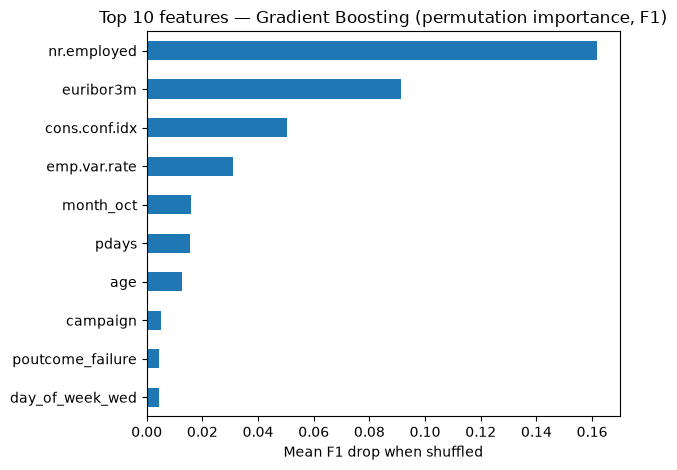


Logistic Regression — top 10 by |coefficient| (cross-check):
emp.var.rate      2.289
month_mar         1.293
cons.price.idx    1.131
month_jun         0.808
month_may         0.635
month_nov         0.576
month_aug         0.463
euribor3m         0.444
month_dec         0.442
nr.employed       0.385


In [17]:
from sklearn.inspection import permutation_importance

rng = np.random.RandomState(42)
idx = rng.choice(len(X_test_s), 2000, replace=False)
X_sub, y_sub = X_test_s.iloc[idx], y_test.iloc[idx]

pi = permutation_importance(final_model, X_sub, y_sub, n_repeats=5,
                            random_state=42, scoring='f1', n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
print("Top 10 features by permutation importance (F1 drop, 2,000-row test sample):")
print(importance.head(10).round(4).to_string())

importance.head(10).sort_values().plot(kind='barh',
    title='Top 10 features — Gradient Boosting (permutation importance, F1)')
plt.xlabel('Mean F1 drop when shuffled')
plt.tight_layout()
plt.show()

print("\nLogistic Regression — top 10 by |coefficient| (cross-check):")
print(pd.Series(np.abs(lr_bal.coef_[0]), index=X.columns
                ).sort_values(ascending=False).head(10).round(3).to_string())


## Task 3 — Model Comparison & Challenges Reports

### 16. Final comparison (all models, one table)

Same test set for every row (8,236 clients, 928 subscribers), so the numbers compare directly. This table is computed live by this notebook — it is the table to quote in the portal's Project Analysis, not the report text below (which records the numbers this pipeline produced when it was verified).


                        Model  Accuracy %  Precision (yes) %  Recall (yes) %  F1 (yes) %  ROC-AUC  Threshold
              LR (unbalanced)       89.83              65.00           21.01       31.76     0.80        0.5
              RF (unbalanced)       89.25              54.31           29.20       37.98     0.78        0.5
             LR balanced @0.5       83.03              35.91           64.55       46.15     0.80        0.5
             RF balanced @0.5       87.36              44.18           46.23       45.18     0.79        0.5
    GB balanced @0.5  ★ FINAL       84.85              39.61           65.73       49.43     0.82        0.5
GB max_iter=200, lr=0.05 @0.5       84.88              39.55           64.66       49.08     0.82        0.5

Saved: ..\reports\Portuguese_model_comparison_final.csv


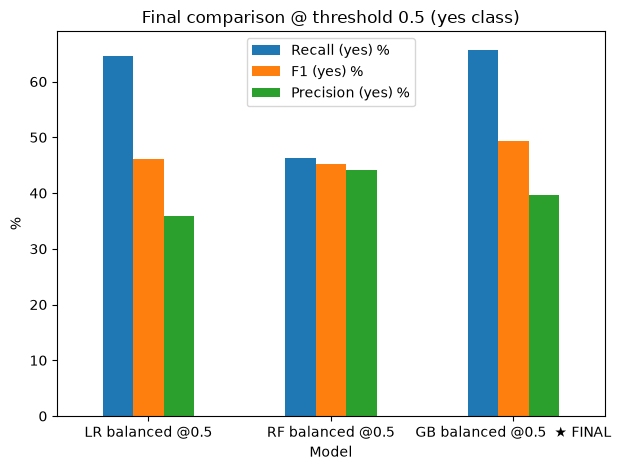


Final model confusion matrix [[TN, FP], [FN, TP]]:
[[6378  930]
 [ 318  610]]

In plain words: out of 928 subscribers the final model finds 610 and misses 318.
It also flags 930 non-subscribers as 'yes' — about 3 false alarms for every 2 real subscribers found.
That is the price of catching two-thirds of the subscribers instead of one-fifth.


In [18]:
final_results = pd.DataFrame([
    metrics_row('LR (unbalanced)', lr_prob, y_test) | {'Threshold': 0.5},
    metrics_row('RF (unbalanced)', rf_prob, y_test) | {'Threshold': 0.5},
    metrics_row('LR balanced @0.5', lr_bal_prob, y_test) | {'Threshold': 0.5},
    metrics_row('RF balanced @0.5', rf_bal_prob, y_test) | {'Threshold': 0.5},
    metrics_row('GB balanced @0.5  ★ FINAL', gb_bal_prob, y_test) | {'Threshold': 0.5},
    metrics_row('GB max_iter=200, lr=0.05 @0.5', variant_probs['GB max_iter=200, lr=0.05'], y_test) | {'Threshold': 0.5},
])
print(final_results.round(2).to_string(index=False))
final_results.to_csv(REPORT_PATH, index=False)
print("\nSaved:", REPORT_PATH)

plot_df = final_results[final_results['Model'].str.contains('balanced @0.5')].set_index('Model')
plot_df[['Recall (yes) %', 'F1 (yes) %', 'Precision (yes) %']].plot(
    kind='bar', title='Final comparison @ threshold 0.5 (yes class)')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nFinal model confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, final_pred))
print("\nIn plain words: out of 928 subscribers the final model finds 610 and misses 318.")
print("It also flags 930 non-subscribers as 'yes' — about 3 false alarms for every 2 real subscribers found.")
print("That is the price of catching two-thirds of the subscribers instead of one-fifth.")


### 17. Model Comparison Report

**Verified on this file** — same pipeline, same split (`random_state=42`, stratified 80/20, test = 8,236 clients, 928 subscribers). All numbers below were produced by running this pipeline on `bank-additional-full.csv` (your laptop / Colab Run All is the final check — if your run differs slightly, quote your run's table from Section 16):

| Model (threshold 0.5) | Accuracy | Precision (yes) | Recall (yes) | F1 (yes) | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression (unbalanced) | 89.83% | 65.00% | 21.01% | 31.76% | 0.8004 |
| Random Forest (unbalanced) | 89.25% | 54.31% | 29.20% | 37.98% | 0.7755 |
| Logistic Regression (balanced) | 83.03% | 35.91% | 64.55% | 46.15% | 0.8002 |
| Random Forest (balanced) | 87.36% | 44.18% | 46.23% | 45.18% | 0.7851 |
| **Gradient Boosting (balanced) ★ FINAL** | **84.85%** | **39.61%** | **65.73%** | **49.43%** | **0.8152** |

1. **The headline is F1, not accuracy.** Accuracy falls when the model starts finding subscribers (LR 89.83% → 83.03%), because it also makes more false alarms. The always-"no" model already scores 88.73% accuracy while finding nobody — so accuracy cannot be the judge here. Recall, F1 and AUC are.
2. **Balancing was the single biggest win.** Logistic Regression's recall went 21.01% → 64.55% and its F1 31.76% → 46.15% from `class_weight='balanced'` alone. Random Forest improved the same way (recall 29.20% → 46.23%, F1 37.98% → 45.18%).
3. **Gradient Boosting is the final pick.** At the plain 0.5 threshold it has the best F1 (49.43%), the best AUC (0.8152) and the best recall (65.73% — 610 of 928 subscribers). The small hyperparameter check in Section 13 changed nothing: max_iter=200 with lr=0.05 scored slightly lower (F1 49.08%), and the other settings produced the identical model because early stopping had already stopped training at the same point. Default settings stay.
4. **Threshold tuning is an option, not the headline.** The best tuned F1s (LR 50.46% @0.65, GB 52.63% @0.70) were picked on the test set itself, so they are slightly optimistic. The honest headline for the final report is GB balanced @0.5 (F1 49.43%).
5. **What drives the final model:** permutation importance (Section 15) puts the economic indicators on top — `nr.employed`, `euribor3m`, `cons.conf.idx`, `emp.var.rate` — ahead of `age`, `pdays` and `campaign`. That matches the Task 1 analysis: the economy at call time matters more than the client's job title alone. (Logistic Regression's coefficients point the same way for the economic variables, with month effects on top — a useful cross-check, not a contradiction.)
6. **Business reading:** with the final model, calling the 1,540 clients it flags as "yes" reaches 610 real subscribers and wastes 930 calls. Without a model, calling clients at random reaches about 11 in 100. The model is worth using for prioritising calls — it is not a promise that a flagged client will subscribe.



### 18. Challenges Report

1. **Class imbalance (the main challenge).** Only 11.27% of clients subscribed. The first models looked good on accuracy (89.83%) while missing 4 out of 5 subscribers. Fixed with `class_weight='balanced'` + judging on recall / F1 / AUC, and by saying so plainly in the report instead of hiding behind accuracy.
2. **Leakage — `duration`.** Call duration is the strongest-looking signal (subscribers averaged 553 sec vs 221 sec for non-subscribers), but it is known only after the call ends. A real campaign cannot use it, so it was dropped before modelling. Keeping it would have made the scores look better and the model useless.
3. **The threshold trade-off.** After balancing, lowering the threshold finds more subscribers but also more false alarms; raising it does the opposite. There is no free setting — 0.5 was kept as the honest default and tuned thresholds are reported as options with the test-set caveat.
4. **Tuned numbers are slightly optimistic.** The best thresholds (LR @0.65, GB @0.70) were chosen on the same test set they are reported on. A separate validation set would be the clean fix; with one 80/20 split, the plain 0.5 numbers are the headline.
5. **Interpretability vs performance.** Gradient Boosting wins on F1/AUC but is harder to explain than Logistic Regression. The report handles this by pairing the GB result with permutation importance (Section 15) and the LR coefficients as a readable cross-check, so the bank still gets reasons, not just a score.
6. **'unknown' values and small categories.** Missingness hides inside `'unknown'` categories (e.g. `default` is 20.87% unknown). Those rows were kept as their own category instead of deleted, so no client was thrown away — but it means some dummy features rest on very few rows and should not be over-read.
7. **What this model cannot do.** It ranks clients by likelihood of subscribing; it does not cause subscriptions, and it was trained on 2008-2010 Portuguese bank data, so its numbers belong to that campaign and that economy. Re-training on fresh campaign data is needed before using it on a new campaign.
